In [3]:
%pip install seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error

In [5]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 57.6 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

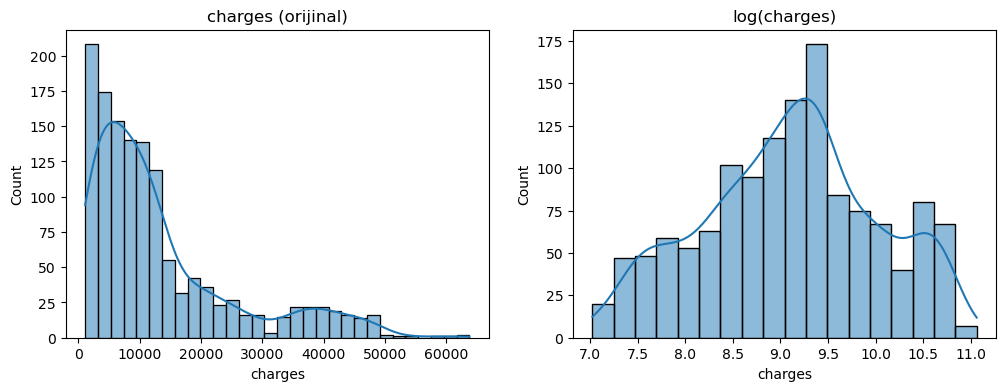

Çarpıklık (orijinal): 1.5158796580240388
Çarpıklık (log)     : -0.09009752473024582


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["charges"], kde=True, ax=ax[0])
ax[0].set_title("charges (orijinal)")

sns.histplot(np.log(df["charges"]), kde=True, ax=ax[1])
ax[1].set_title("log(charges)")

plt.show()

print("Çarpıklık (orijinal):", df["charges"].skew())
print("Çarpıklık (log)     :", np.log(df["charges"]).skew())

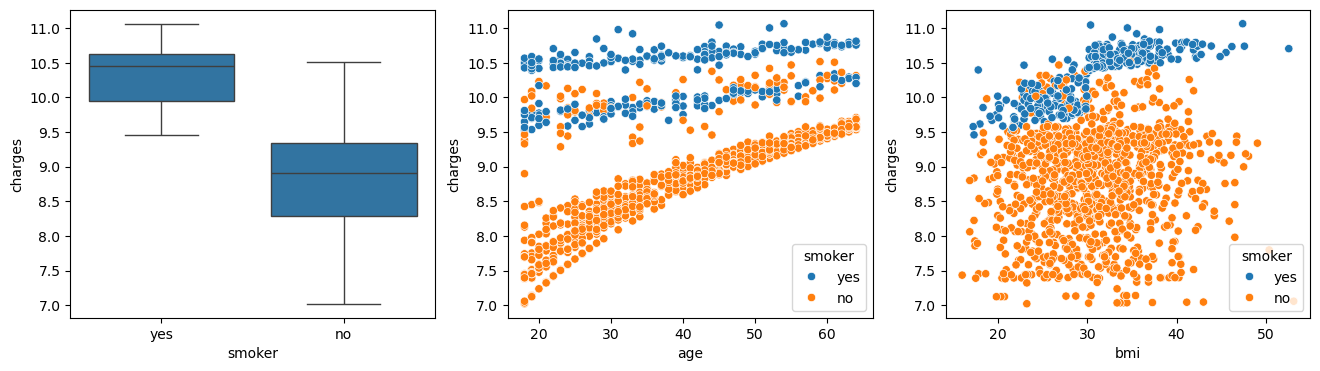

In [10]:
df["charges"] = np.log(df["charges"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="smoker", y="charges", ax=ax[0])
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", ax=ax[1])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", ax=ax[2])

plt.show()

In [11]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="charges")   # bağımsız değişkenler
y = df["charges"]                # bağımlı değişken

X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


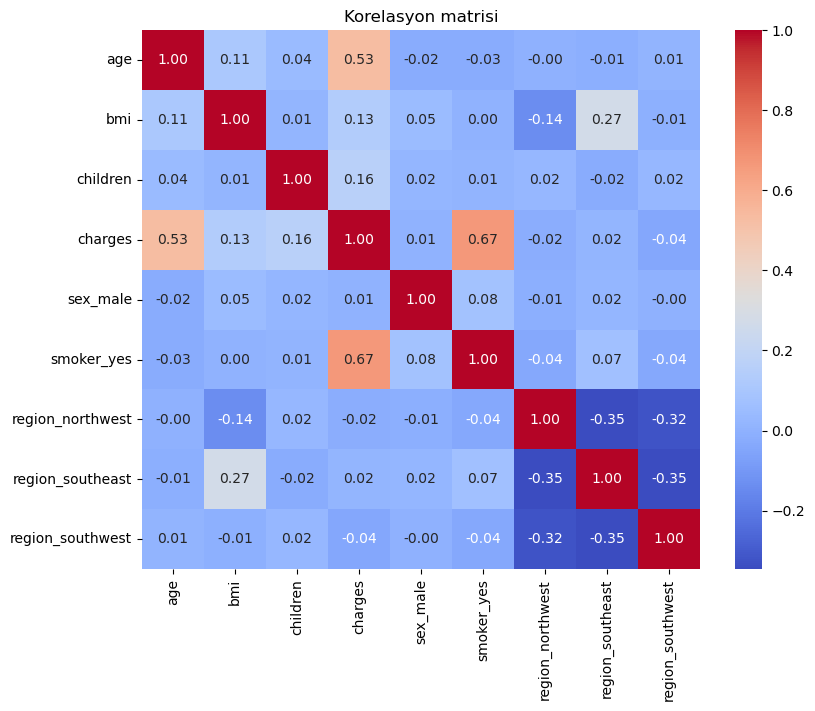

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasyon matrisi")
plt.show()

In [13]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xc = sm.add_constant(X)   # VIF doğru hesaplansın diye sabit terim ekliyoruz

vif = pd.DataFrame()
vif["degisken"] = X.columns
vif["VIF"] = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
vif

,degisken,VIF
0,age,1.016822
1,bmi,1.106630
2,children,1.004011
3,sex_male,1.008900
4,smoker_yes,1.012074
5,region_northwest,1.518823
6,region_southeast,1.652230
7,region_southwest,1.529411


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Eğitim:", X_train.shape)
print("Test  :", X_test.shape)

Eğitim: (1070, 8)
Test  : (268, 8)


In [15]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [16]:
ols = LinearRegression()
ols.fit(X_train_s, y_train)

print("OLS test R²:", ols.score(X_test_s, y_test))

OLS test R²: 0.8047311493462984


In [17]:
ridge_params = {"alpha": np.logspace(-3, 3, 50)}

ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5, scoring="r2")
ridge_grid.fit(X_train_s, y_train)

print("En iyi alpha :", ridge_grid.best_params_)
print("En iyi CV R² :", ridge_grid.best_score_)

En iyi alpha : {'alpha': np.float64(3.5564803062231287)}
En iyi CV R² : 0.751298118961292


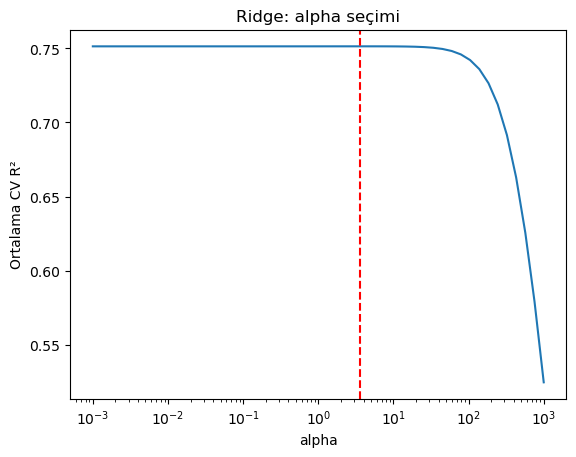

In [18]:
plt.plot(ridge_params["alpha"], ridge_grid.cv_results_["mean_test_score"])
plt.axvline(ridge_grid.best_params_["alpha"], color="red", linestyle="--")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Ortalama CV R²")
plt.title("Ridge: alpha seçimi")
plt.show()

In [19]:
lasso_params = {"alpha": np.logspace(-4, 0, 50)}

lasso_grid = GridSearchCV(Lasso(max_iter=10000), lasso_params, cv=5, scoring="r2")
lasso_grid.fit(X_train_s, y_train)

print("En iyi alpha :", lasso_grid.best_params_)
print("En iyi CV R² :", lasso_grid.best_score_)

En iyi alpha : {'alpha': np.float64(0.0005428675439323859)}
En iyi CV R² : 0.7512866552492802


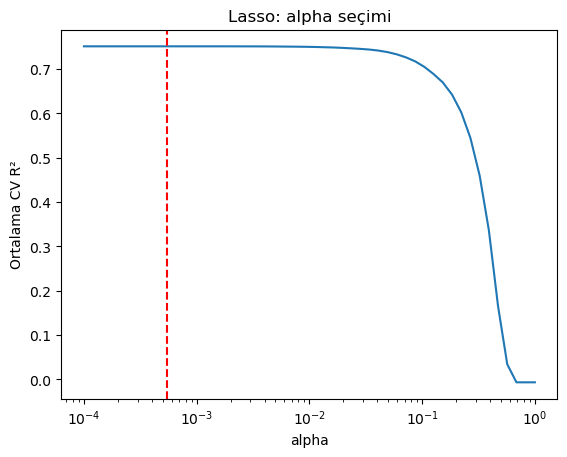

In [20]:
plt.plot(lasso_params["alpha"], lasso_grid.cv_results_["mean_test_score"])
plt.axvline(lasso_grid.best_params_["alpha"], color="red", linestyle="--")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Ortalama CV R²")
plt.title("Lasso: alpha seçimi")
plt.show()

In [21]:
en_params = {"alpha": [0.0001, 0.001, 0.01, 0.1, 1],
             "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}

en_grid = GridSearchCV(ElasticNet(max_iter=10000), en_params, cv=5, scoring="r2")
en_grid.fit(X_train_s, y_train)

print("En iyi parametreler :", en_grid.best_params_)
print("En iyi CV R²        :", en_grid.best_score_)

En iyi parametreler : {'alpha': 0.001, 'l1_ratio': 0.3}
En iyi CV R²        : 0.751289729002829


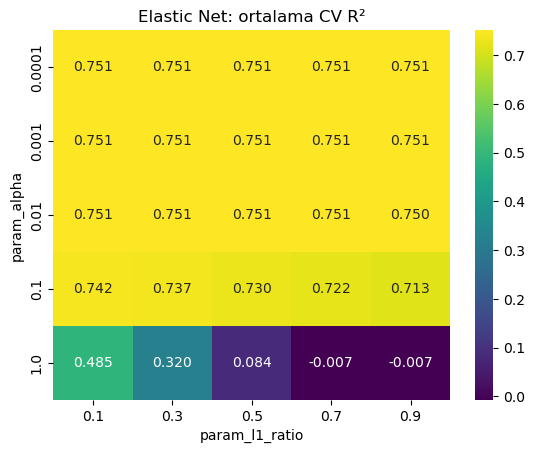

In [22]:
sonuc = pd.DataFrame(en_grid.cv_results_)
tablo = sonuc.pivot_table(index="param_alpha", columns="param_l1_ratio", values="mean_test_score")

sns.heatmap(tablo, annot=True, fmt=".3f", cmap="viridis")
plt.title("Elastic Net: ortalama CV R²")
plt.show()

In [23]:
modeller = {"OLS": ols,
            "Ridge": ridge_grid.best_estimator_,
            "Lasso": lasso_grid.best_estimator_,
            "Elastic Net": en_grid.best_estimator_}

sonuclar = []
for ad, model in modeller.items():
    tahmin = model.predict(X_test_s)
    r2 = r2_score(y_test, tahmin)
    rmse = np.sqrt(mean_squared_error(y_test, tahmin))
    sonuclar.append([ad, r2, rmse])

sonuclar = pd.DataFrame(sonuclar, columns=["Model", "R2", "RMSE"])
sonuclar

,Model,R2,RMSE
0,OLS,0.804731,0.419016
1,Ridge,0.804545,0.419216
2,Lasso,0.804538,0.419223
3,Elastic Net,0.804587,0.419170


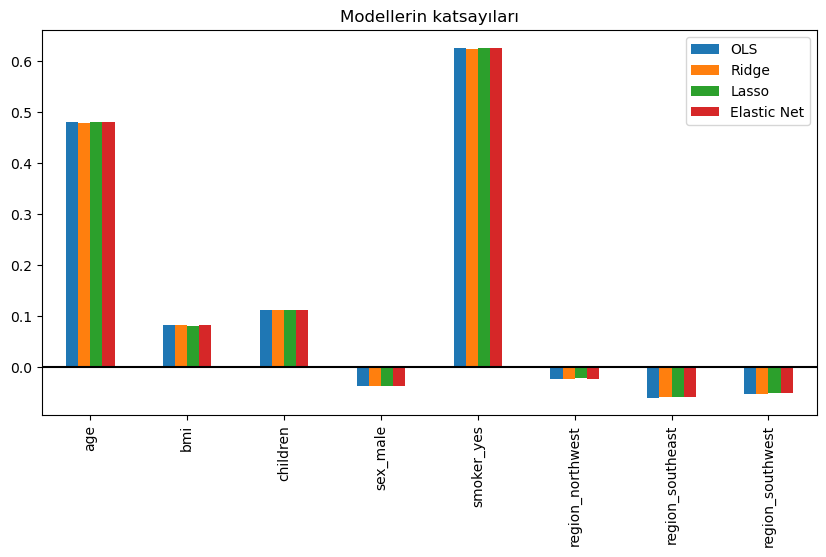

,OLS,Ridge,Lasso,Elastic Net
age,0.481744,0.480070,0.481272,0.481130
bmi,0.082150,0.081947,0.081342,0.081662
children,0.112363,0.112121,0.111839,0.112023
sex_male,-0.037164,-0.036888,-0.036550,-0.036767
smoker_yes,0.627111,0.624925,0.626515,0.626320
region_northwest,-0.024068,-0.023691,-0.022407,-0.023074
region_southeast,-0.060014,-0.059393,-0.058096,-0.058826
region_southwest,-0.052835,-0.052358,-0.051095,-0.051776


In [24]:
katsayilar = pd.DataFrame({"OLS": ols.coef_,
                           "Ridge": ridge_grid.best_estimator_.coef_,
                           "Lasso": lasso_grid.best_estimator_.coef_,
                           "Elastic Net": en_grid.best_estimator_.coef_},
                          index=X.columns)

katsayilar.plot(kind="bar", figsize=(10, 5))
plt.axhline(0, color="black")
plt.title("Modellerin katsayıları")
plt.show()

katsayilar

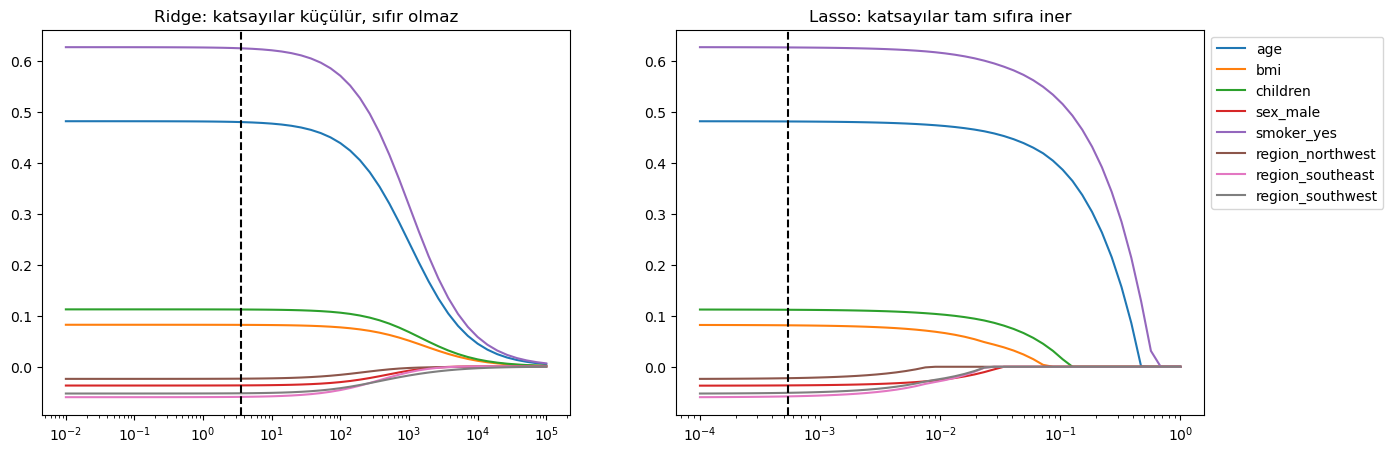

In [25]:
ridge_alphas = np.logspace(-2, 5, 50)
ridge_kats = []
for a in ridge_alphas:
    model = Ridge(alpha=a).fit(X_train_s, y_train)
    ridge_kats.append(model.coef_)

lasso_alphas = np.logspace(-4, 0, 50)
lasso_kats = []
for a in lasso_alphas:
    model = Lasso(alpha=a, max_iter=10000).fit(X_train_s, y_train)
    lasso_kats.append(model.coef_)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(ridge_alphas, ridge_kats)
ax[0].axvline(ridge_grid.best_params_["alpha"], color="black", linestyle="--")
ax[0].set_xscale("log")
ax[0].set_title("Ridge: katsayılar küçülür, sıfır olmaz")

ax[1].plot(lasso_alphas, lasso_kats)
ax[1].axvline(lasso_grid.best_params_["alpha"], color="black", linestyle="--")
ax[1].set_xscale("log")
ax[1].set_title("Lasso: katsayılar tam sıfıra iner")
ax[1].legend(X.columns, bbox_to_anchor=(1, 1))

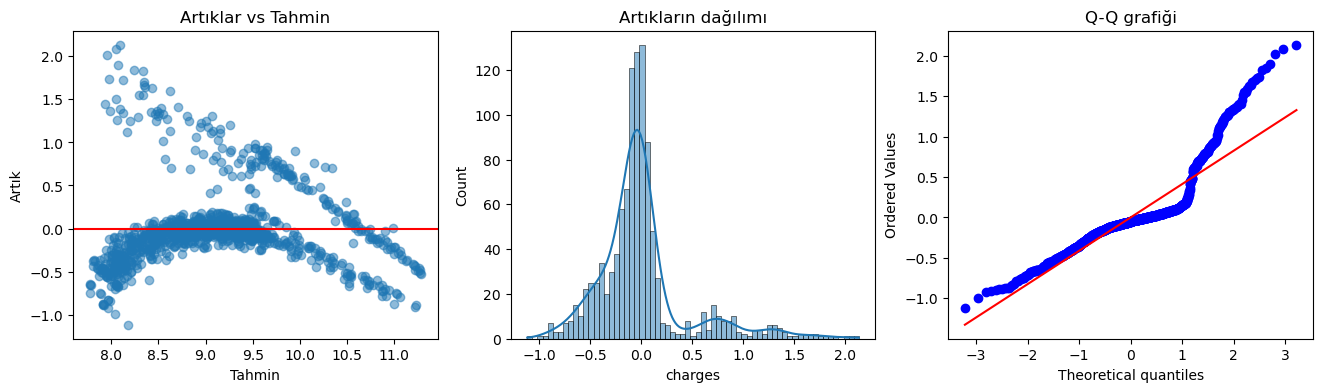

In [26]:
from scipy import stats

model = en_grid.best_estimator_
tahmin = model.predict(X_train_s)
artik = y_train - tahmin

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(tahmin, artik, alpha=0.5)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("Tahmin")
ax[0].set_ylabel("Artık")
ax[0].set_title("Artıklar vs Tahmin")

sns.histplot(artik, kde=True, ax=ax[1])
ax[1].set_title("Artıkların dağılımı")

stats.probplot(artik, plot=ax[2])
ax[2].set_title("Q-Q grafiği")

plt.show()

In [27]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

print("Shapiro-Wilk p  :", stats.shapiro(artik).pvalue)
print("Breusch-Pagan p :", het_breuschpagan(artik, sm.add_constant(X_train_s))[1])
print("Durbin-Watson   :", durbin_watson(artik))

Shapiro-Wilk p  : 1.738658358272099e-31
Breusch-Pagan p : 1.7417682106907485e-12
Durbin-Watson   : 2.0337847504443265


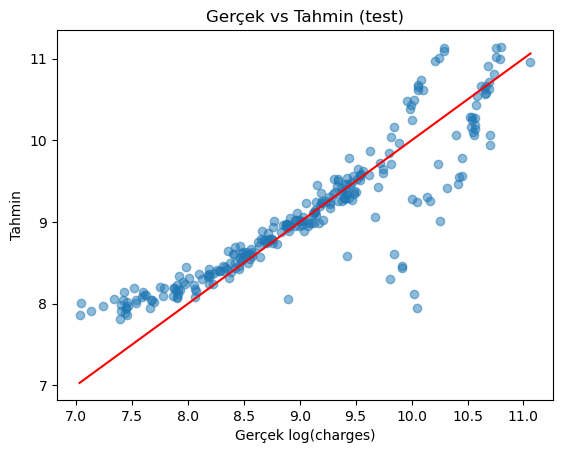

In [28]:
test_tahmin = model.predict(X_test_s)

plt.scatter(y_test, test_tahmin, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Gerçek log(charges)")
plt.ylabel("Tahmin")
plt.title("Gerçek vs Tahmin (test)")
plt.show()